In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import drive
drive.mount('/content/drive')

sns.set_theme(style="whitegrid")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [28]:
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/wine.csv")
df

,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,3,13.71,5.65,2.45,20.5,95,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740
174,3,13.40,3.91,2.48,23.0,102,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750
175,3,13.27,4.28,2.26,20.0,120,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835
176,3,13.17,2.59,2.37,20.0,120,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840


In [29]:
# 데이터 구조 확인
print("데이터 크기:", df.shape)

print("\n처음 5개 데이터")
display(df.head())

print("\n변수 이름")
print(df.columns.tolist())

print("\n자료형")
print(df.dtypes)

print("\n데이터 정보")
df.info()

데이터 크기: (178, 14)

처음 5개 데이터


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735



변수 이름
['Wine', 'Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']

자료형
Wine                      int64
Alcohol                 float64
Malic.acid              float64
Ash                     float64
Acl                     float64
Mg                        int64
Phenols                 float64
Flavanoids              float64
Nonflavanoid.phenols    float64
Proanth                 float64
Color.int               float64
Hue                     float64
OD                      float64
Proline                   int64
dtype: object

데이터 정보
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Wine                  178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic.acid            178 non-null    float64
 3   As

In [30]:
print("변수별 결측치 개수")
print(df.isnull().sum())

print("\n중복 행 개수")
print(df.duplicated().sum())

변수별 결측치 개수
Wine                    0
Alcohol                 0
Malic.acid              0
Ash                     0
Acl                     0
Mg                      0
Phenols                 0
Flavanoids              0
Nonflavanoid.phenols    0
Proanth                 0
Color.int               0
Hue                     0
OD                      0
Proline                 0
dtype: int64

중복 행 개수
0


In [31]:
numeric_cols = [c for c in df.columns if c != 'Wine']   # 13개 연속형 변수
target_col = 'Wine'

# 시각화용 핵심 변수 (뒤의 분리도 분석에서 품종 차이가 큰 변수들)
key_cols = ['Alcohol', 'Flavanoids', 'Color.int', 'Proline', 'OD']

print(len(numeric_cols), "개 변수:", numeric_cols)

13 개 변수: ['Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']


In [32]:
print("레이블 종류")
print(df[target_col].unique())

print("\n레이블별 개수")
print(df[target_col].value_counts().sort_index())

print("\n레이블별 비율")
print((df[target_col].value_counts(normalize=True).sort_index() * 100).round(1))

레이블 종류
[1 2 3]

레이블별 개수
Wine
1    59
2    71
3    48
Name: count, dtype: int64

레이블별 비율
Wine
1    33.1
2    39.9
3    27.0
Name: proportion, dtype: float64


In [33]:
df['Wine'].value_counts()

,count
Wine,
2,71
1,59
3,48


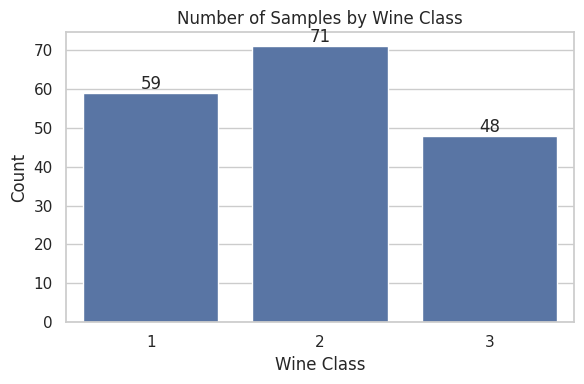

In [34]:
# countplot은 각 범주에 몇 개의 데이터가 존재하는지 막대그래프로 보여준다
plt.figure(figsize=(6, 4))

ax = sns.countplot(data=df, x=target_col, order=sorted(df[target_col].unique()))

for container in ax.containers:
    ax.bar_label(container)

plt.title("Number of Samples by Wine Class")
plt.xlabel("Wine Class")
plt.ylabel("Count")

plt.tight_layout()
plt.show()

In [35]:
# describe()는 수치형 변수의 기본적인 통계량을 보여준다.
display(df[numeric_cols].describe().round(3))

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
count,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000,178.000
mean,13.001,2.336,2.367,19.495,99.742,2.295,2.029,0.362,1.591,5.058,0.957,2.612,746.893
std,0.812,1.117,0.274,3.340,14.282,0.626,0.999,0.124,0.572,2.318,0.229,0.710,314.907
min,11.030,0.740,1.360,10.600,70.000,0.980,0.340,0.130,0.410,1.280,0.480,1.270,278.000
25%,12.362,1.602,2.210,17.200,88.000,1.742,1.205,0.270,1.250,3.220,0.782,1.938,500.500
50%,13.050,1.865,2.360,19.500,98.000,2.355,2.135,0.340,1.555,4.690,0.965,2.780,673.500
75%,13.678,3.082,2.558,21.500,107.000,2.800,2.875,0.438,1.950,6.200,1.120,3.170,985.000
max,14.830,5.800,3.230,30.000,162.000,3.880,5.080,0.660,3.580,13.000,1.710,4.000,1680.000


In [36]:
#groupby()를 이용하면 데이터를 품종별로 나누어 평균과 표준편차를 계산할 수 있다.
print("품종별 평균")
display(df.groupby(target_col)[numeric_cols].mean().round(3))

print("품종별 표준편차")
display(df.groupby(target_col)[numeric_cols].std().round(3))

품종별 평균


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Wine,,,,,,,,,,,,,
1,13.745,2.011,2.456,17.037,106.339,2.840,2.982,0.290,1.899,5.528,1.062,3.158,1115.712
2,12.279,1.933,2.245,20.238,94.549,2.259,2.081,0.364,1.630,3.087,1.056,2.785,519.507
3,13.154,3.334,2.437,21.417,99.312,1.679,0.781,0.448,1.154,7.396,0.683,1.684,629.896


품종별 표준편차


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Wine,,,,,,,,,,,,,
1,0.462,0.689,0.227,2.546,10.499,0.339,0.397,0.070,0.412,1.239,0.116,0.357,221.521
2,0.538,1.016,0.315,3.350,16.753,0.545,0.706,0.124,0.602,0.925,0.203,0.497,157.211
3,0.530,1.088,0.185,2.258,10.890,0.357,0.294,0.124,0.409,2.311,0.114,0.272,115.097


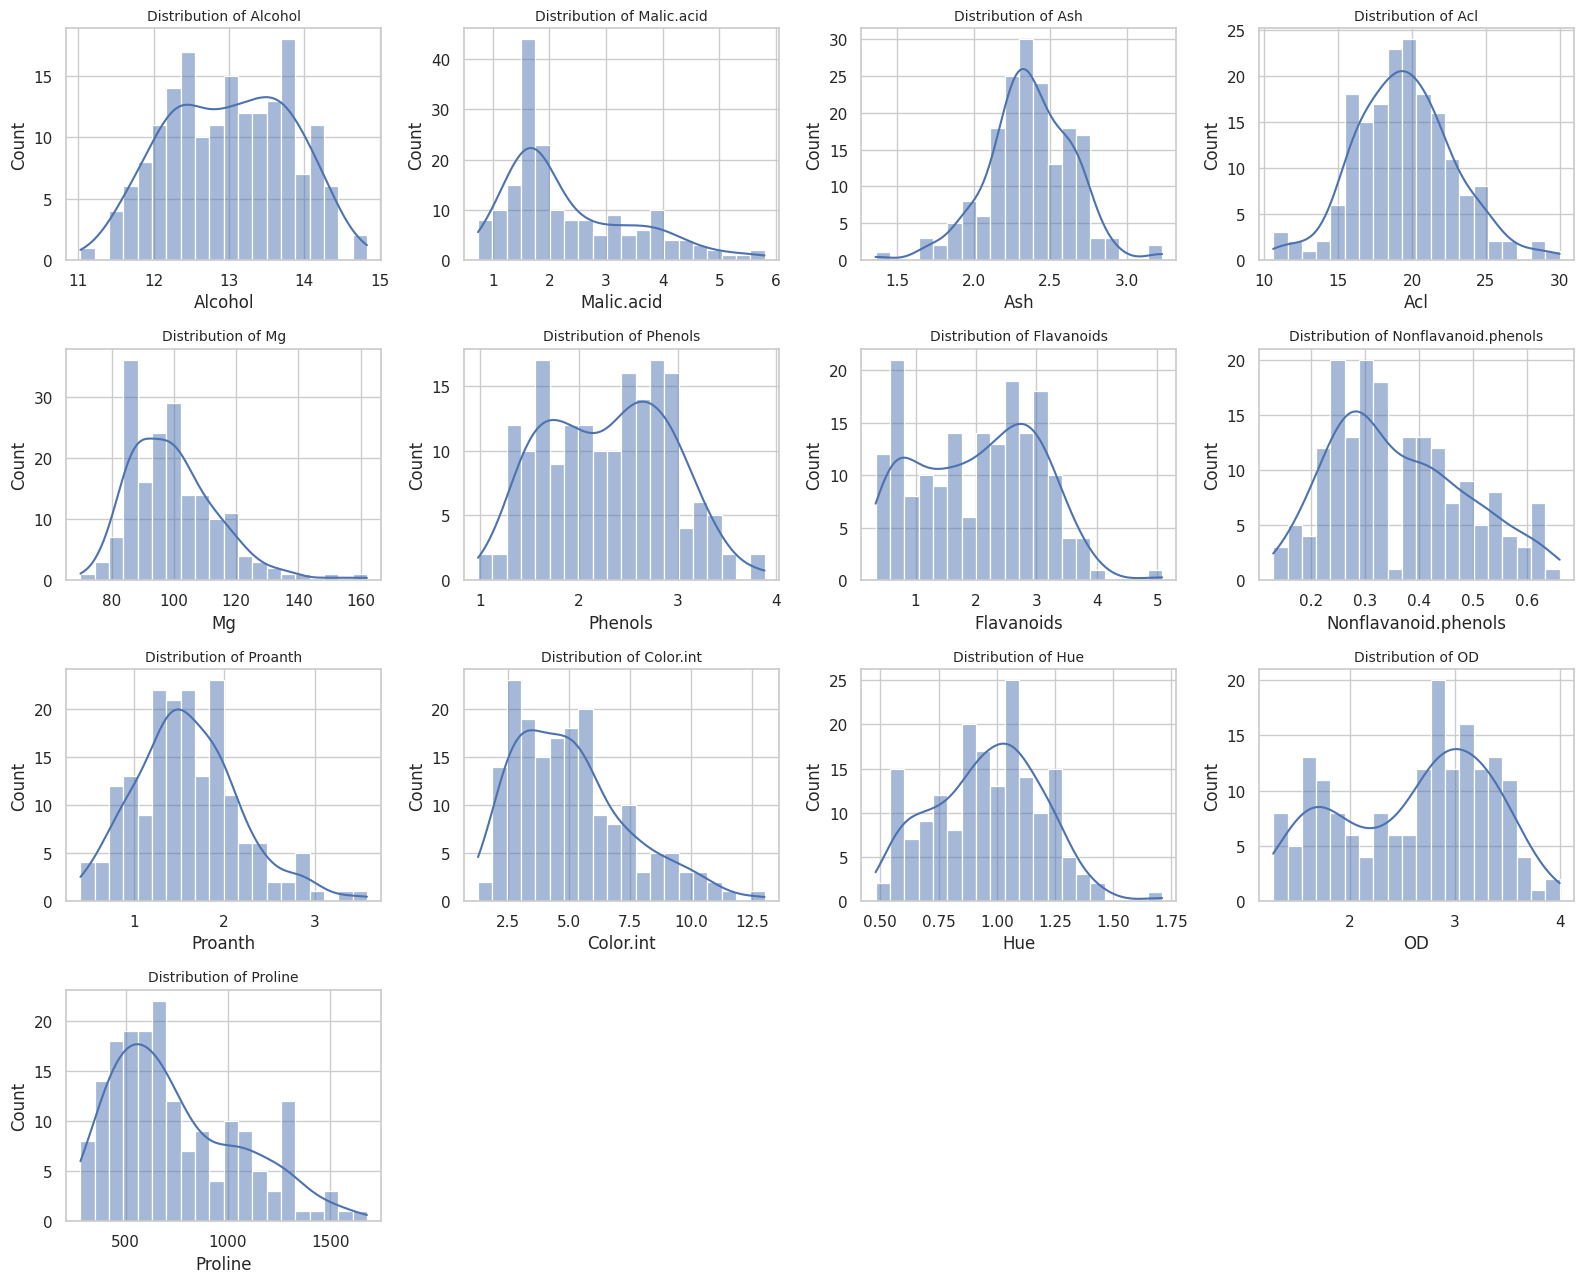

왜도(Skewness) - 절댓값이 클수록 한쪽으로 치우친 분포
Mg                      1.10
Malic.acid              1.04
Color.int               0.87
Proline                 0.77
Proanth                 0.52
Nonflavanoid.phenols    0.45
Acl                     0.21
Phenols                 0.09
Flavanoids              0.03
Hue                     0.02
Alcohol                -0.05
Ash                    -0.18
OD                     -0.31
dtype: float64


In [37]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, bins=20, kde=True, ax=axes[i])
    axes[i].set_title(f"Distribution of {col}", fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

print("왜도(Skewness) - 절댓값이 클수록 한쪽으로 치우친 분포")
print(df[numeric_cols].skew().round(2).sort_values(ascending=False))

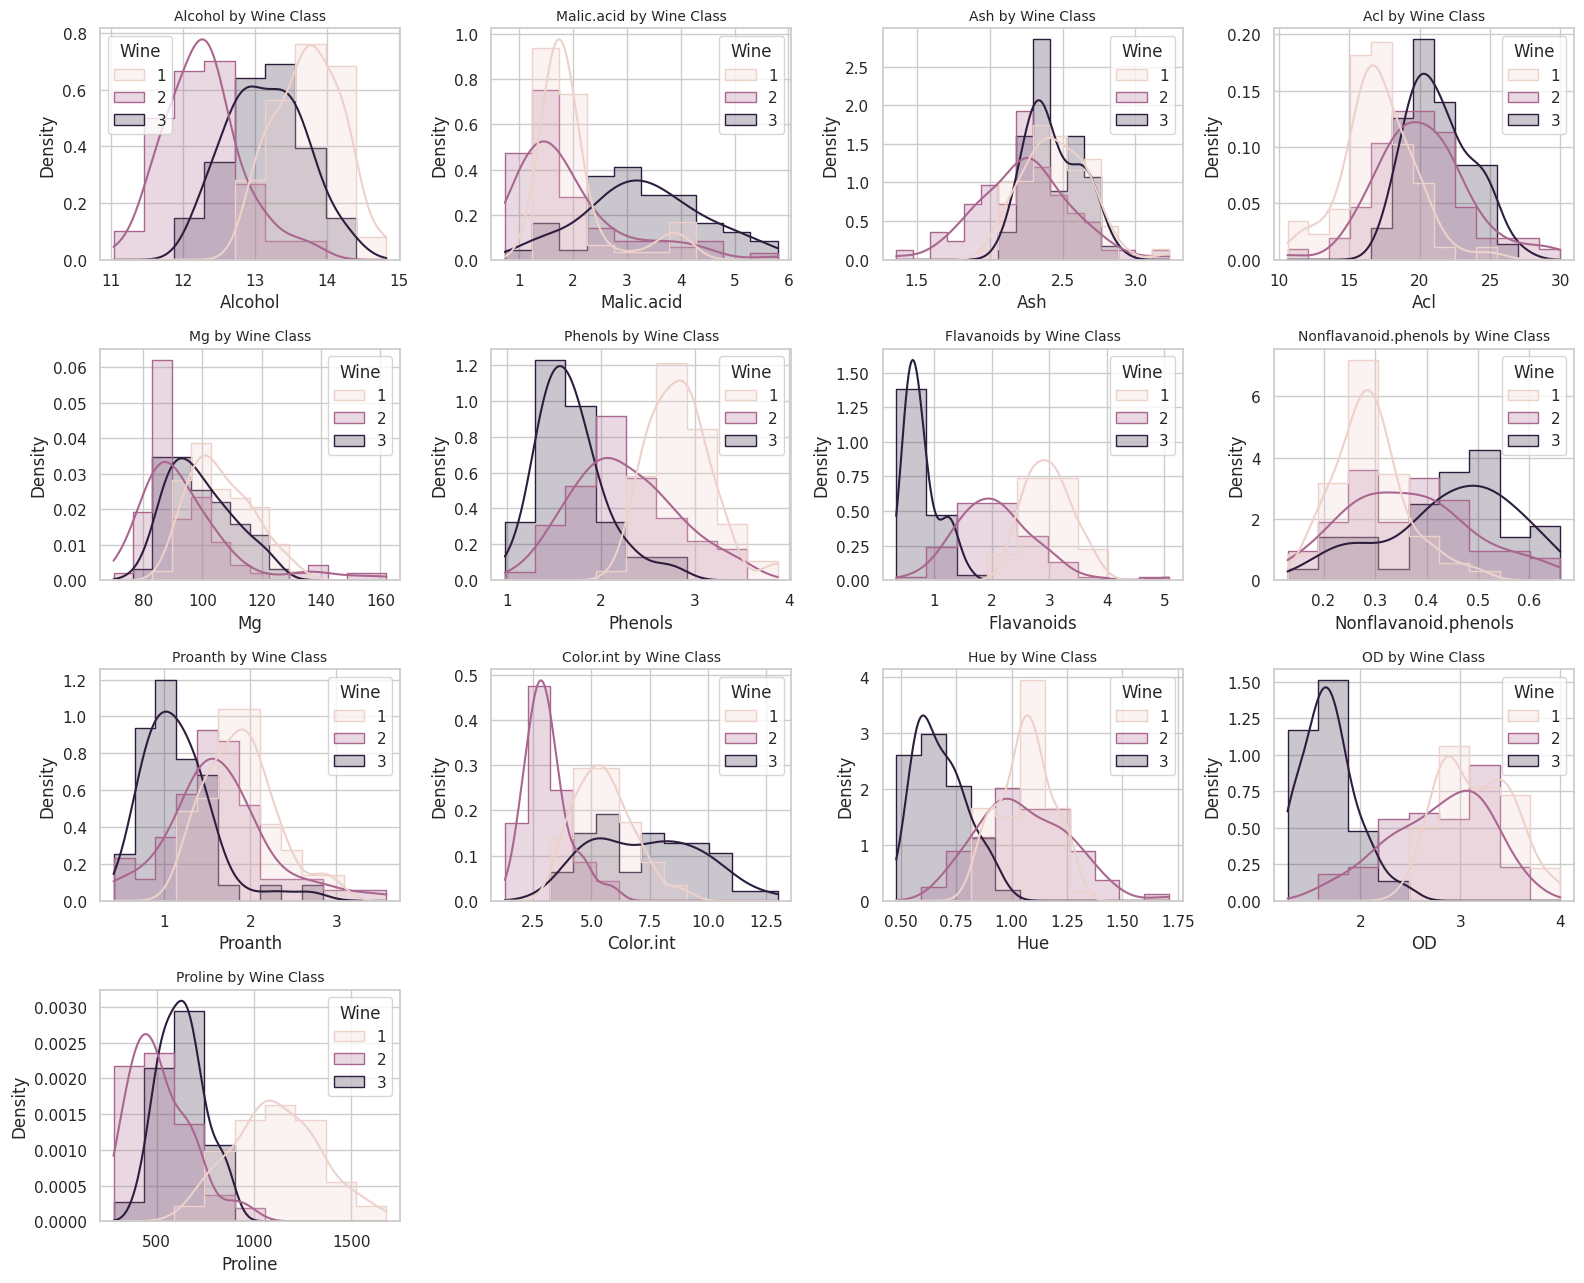

In [38]:
fig, axes = plt.subplots(4, 4, figsize=(16, 13))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.histplot(data=df, x=col, hue=target_col, kde=True, element="step",
                 stat="density", common_norm=False, ax=axes[i],
                 hue_order=sorted(df[target_col].unique()))
    axes[i].set_title(f"{col} by Wine Class", fontsize=10)

for j in range(len(numeric_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

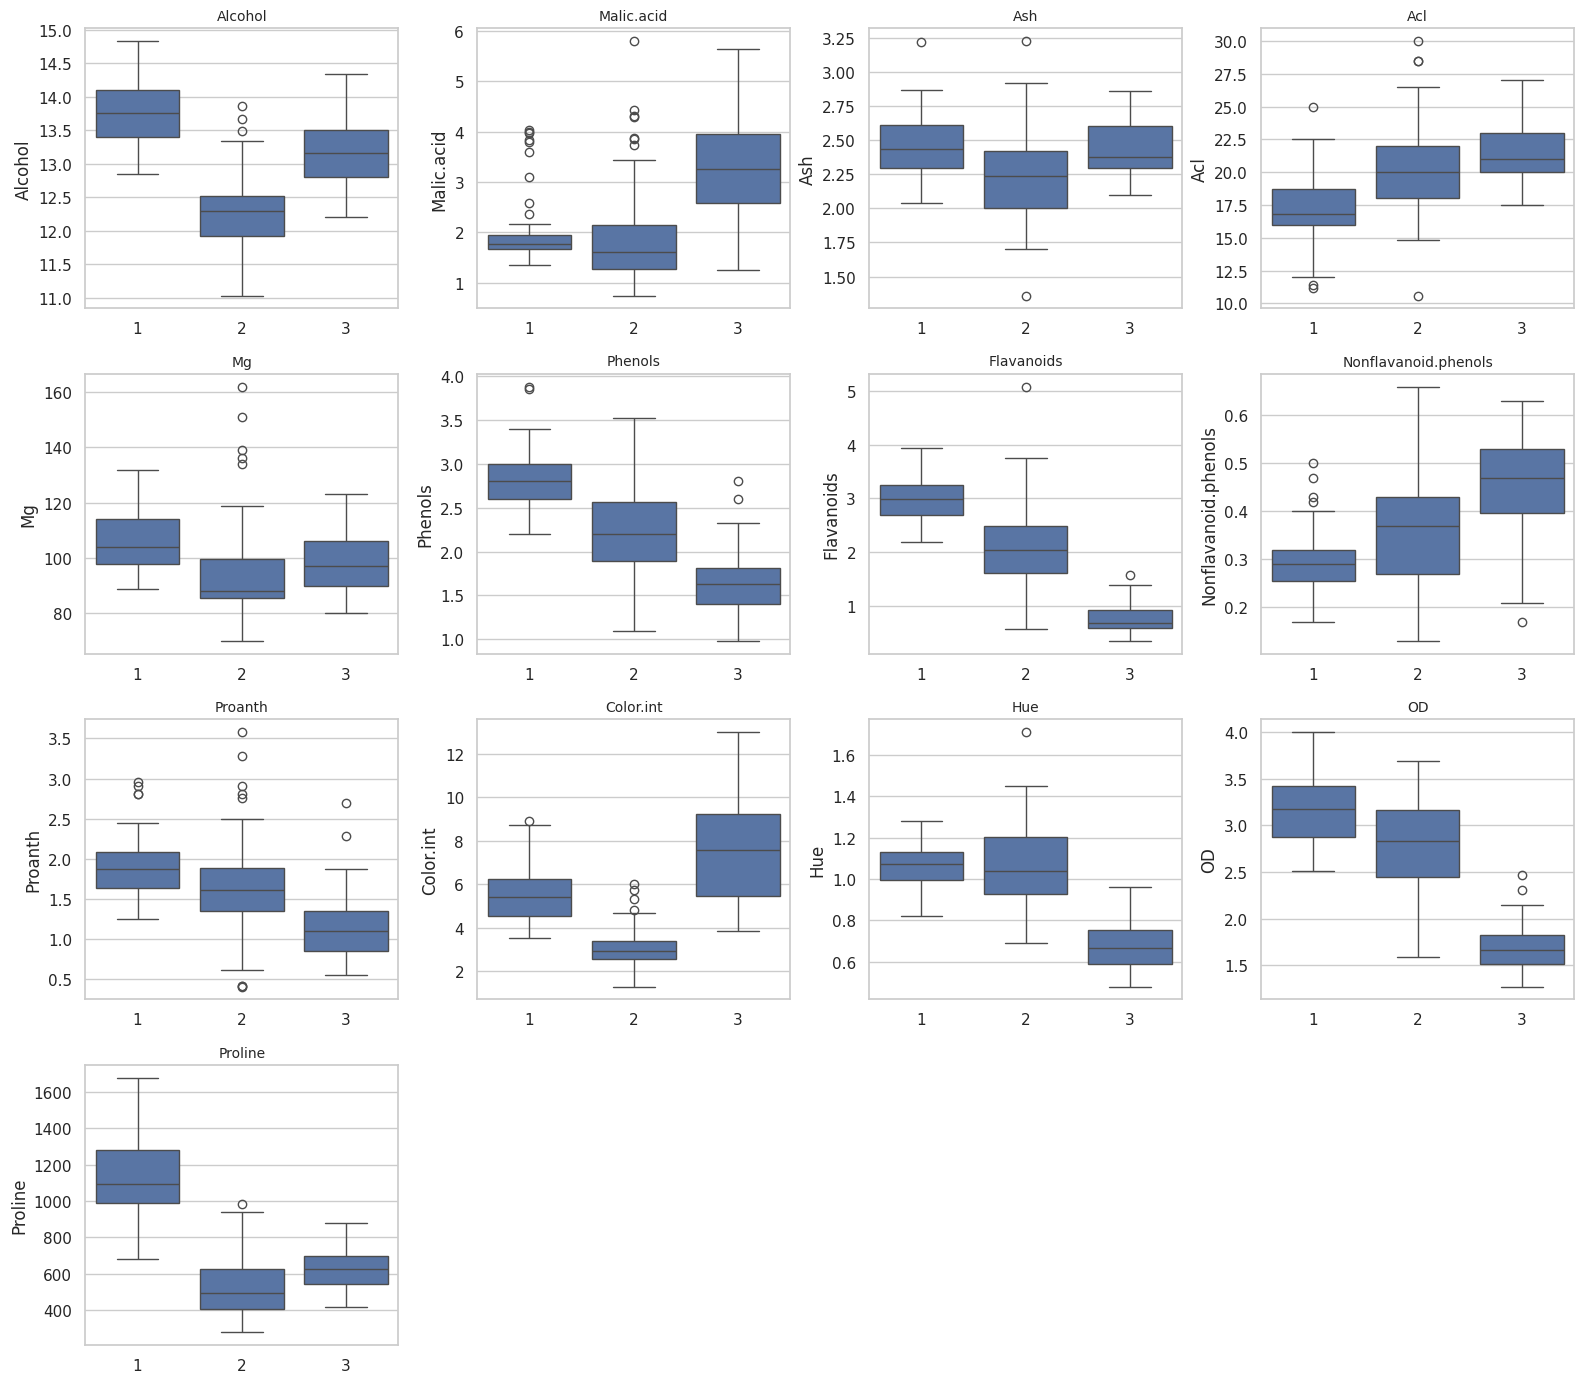

In [39]:
order = sorted(df[target_col].unique())

fig, axes = plt.subplots(4, 4, figsize=(16, 14))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    sns.boxplot(data=df, x=target_col, y=col, order=order, ax=axes[i])
    axes[i].set_title(col, fontsize=10)
    axes[i].set_xlabel("")

for j in range(len(numeric_cols), len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

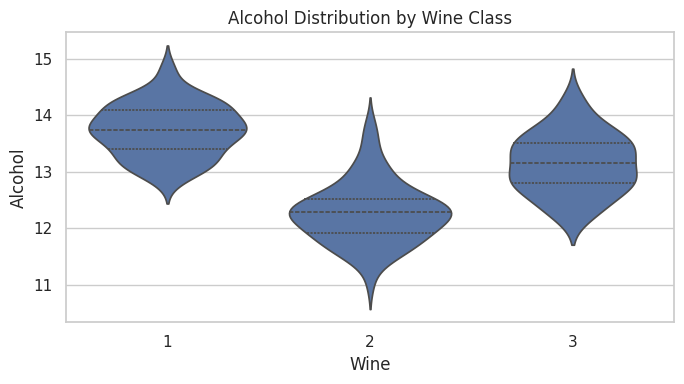

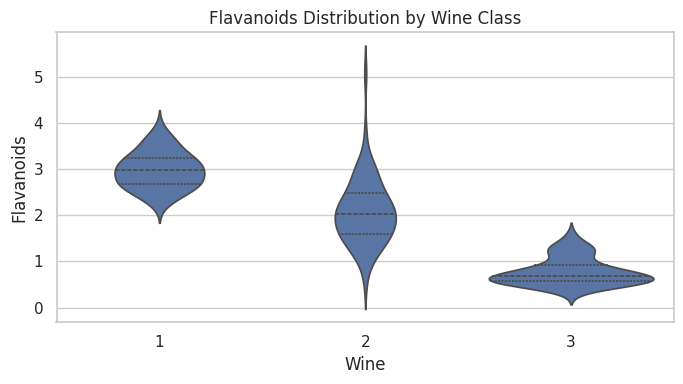

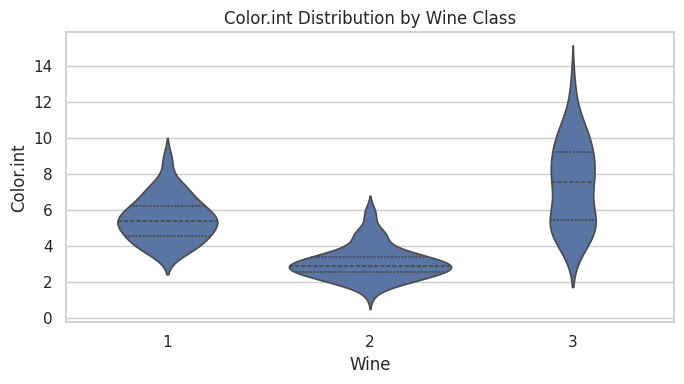

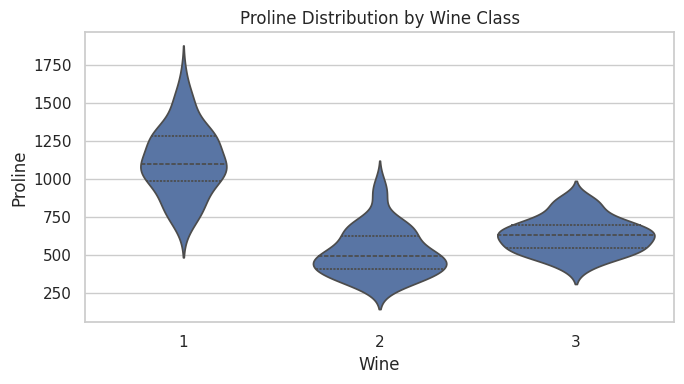

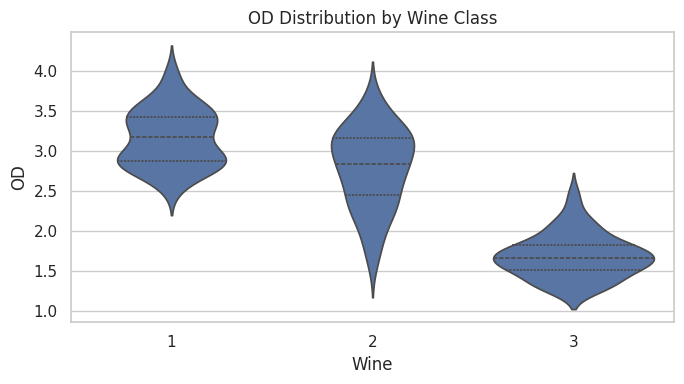

In [40]:
for col in key_cols:

    plt.figure(figsize=(7, 4))

    sns.violinplot(data=df, x=target_col, y=col, order=order, inner="quartile")

    plt.title(f"{col} Distribution by Wine Class")

    plt.tight_layout()
    plt.show()

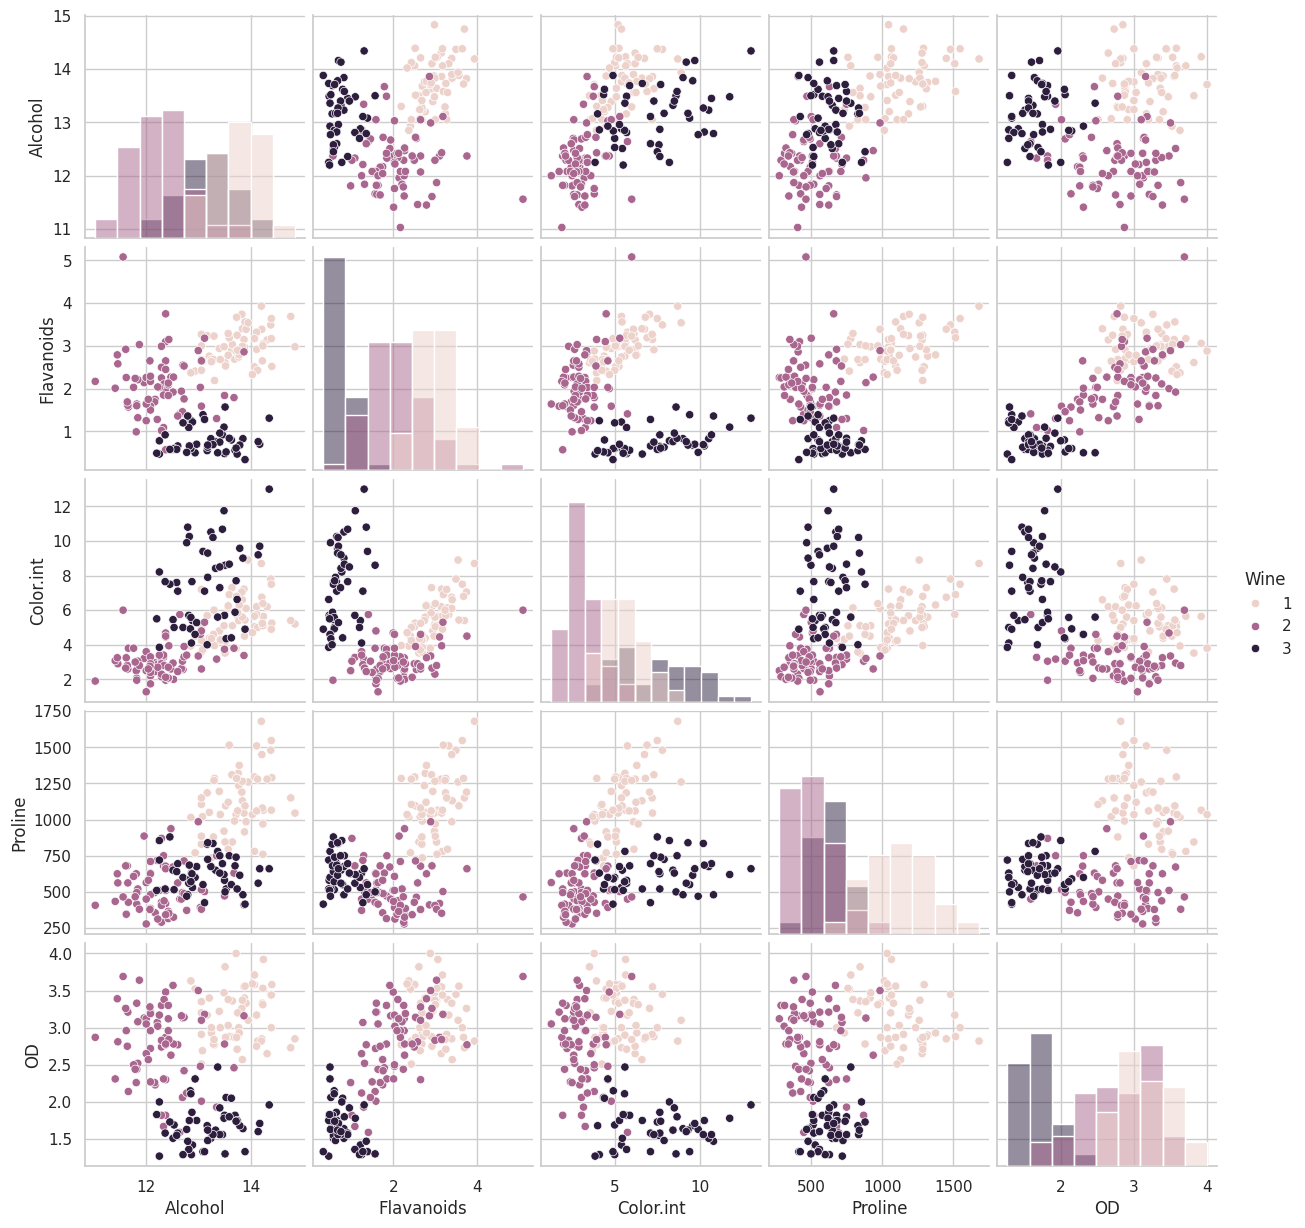

In [41]:
sns.pairplot(df, vars=key_cols, hue=target_col, hue_order=order, diag_kind="hist")

plt.show()

In [42]:
corr = df[numeric_cols].corr()

display(corr.round(3))

,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Alcohol,1.000,0.094,0.212,-0.310,0.271,0.289,0.237,-0.156,0.137,0.546,-0.072,0.072,0.644
Malic.acid,0.094,1.000,0.164,0.289,-0.055,-0.335,-0.411,0.293,-0.221,0.249,-0.561,-0.369,-0.192
Ash,0.212,0.164,1.000,0.443,0.287,0.129,0.115,0.186,0.010,0.259,-0.075,0.004,0.224
Acl,-0.310,0.289,0.443,1.000,-0.083,-0.321,-0.351,0.362,-0.197,0.019,-0.274,-0.277,-0.441
Mg,0.271,-0.055,0.287,-0.083,1.000,0.214,0.196,-0.256,0.236,0.200,0.055,0.066,0.393
Phenols,0.289,-0.335,0.129,-0.321,0.214,1.000,0.865,-0.450,0.612,-0.055,0.434,0.700,0.498
Flavanoids,0.237,-0.411,0.115,-0.351,0.196,0.865,1.000,-0.538,0.653,-0.172,0.543,0.787,0.494
Nonflavanoid.phenols,-0.156,0.293,0.186,0.362,-0.256,-0.450,-0.538,1.000,-0.366,0.139,-0.263,-0.503,-0.311
Proanth,0.137,-0.221,0.010,-0.197,0.236,0.612,0.653,-0.366,1.000,-0.025,0.296,0.519,0.330
Color.int,0.546,0.249,0.259,0.019,0.200,-0.055,-0.172,0.139,-0.025,1.000,-0.522,-0.429,0.316


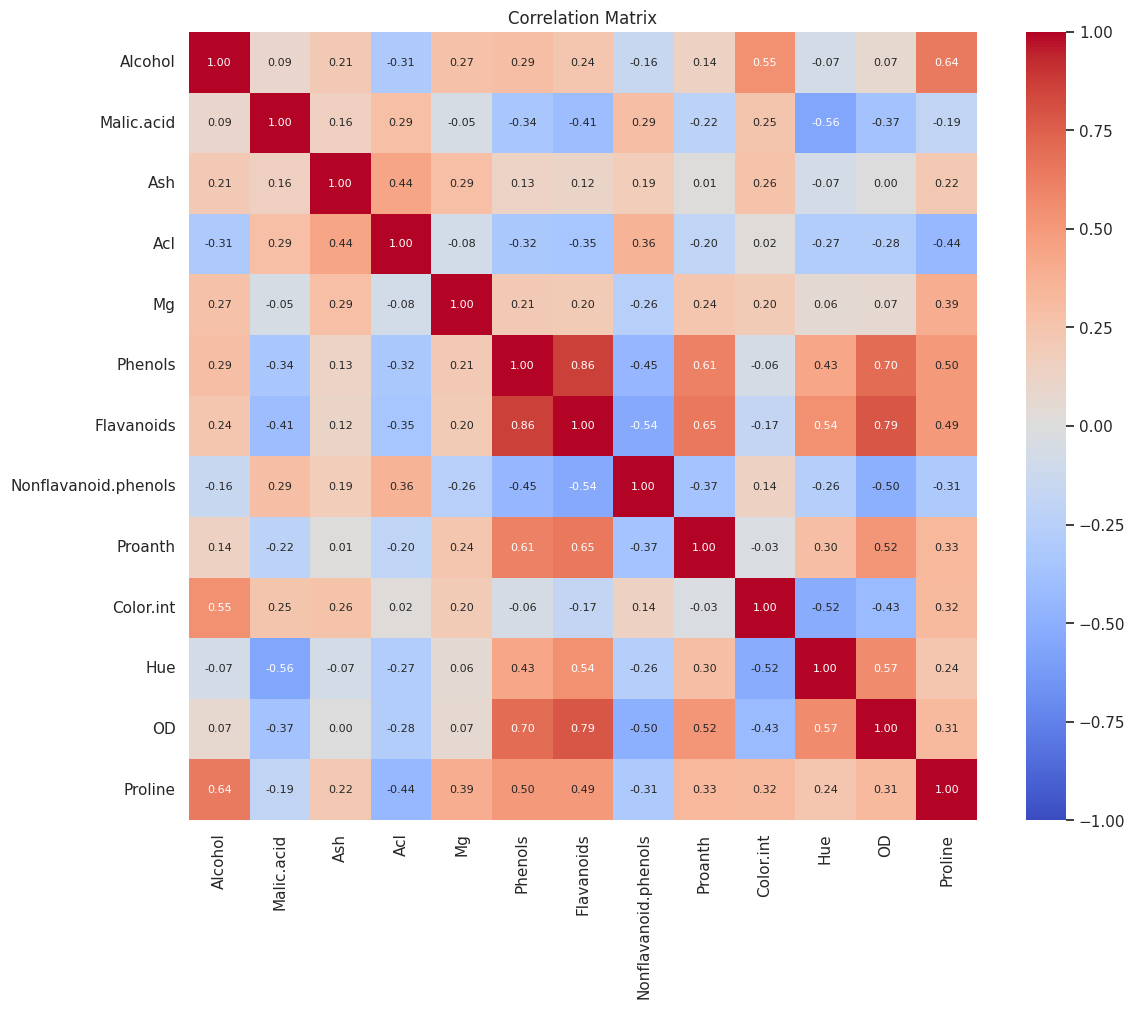

In [43]:
plt.figure(figsize=(12, 10))

sns.heatmap(corr, annot=True, fmt=".2f", square=True, cmap="coolwarm",
            vmin=-1, vmax=1, annot_kws={"size": 8})

plt.title("Correlation Matrix")

plt.tight_layout()
plt.show()

In [44]:
pairs = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
        .stack()
        .reset_index()
)
pairs.columns = ['Feature 1', 'Feature 2', 'Correlation']
pairs['|r|'] = pairs['Correlation'].abs()

display(pairs[pairs['|r|'] >= 0.6].sort_values('|r|', ascending=False).round(3).reset_index(drop=True))

,Feature 1,Feature 2,Correlation,|r|
0,Phenols,Flavanoids,0.865,0.865
1,Flavanoids,OD,0.787,0.787
2,Phenols,OD,0.700,0.700
3,Flavanoids,Proanth,0.653,0.653
4,Alcohol,Proline,0.644,0.644
5,Phenols,Proanth,0.612,0.612


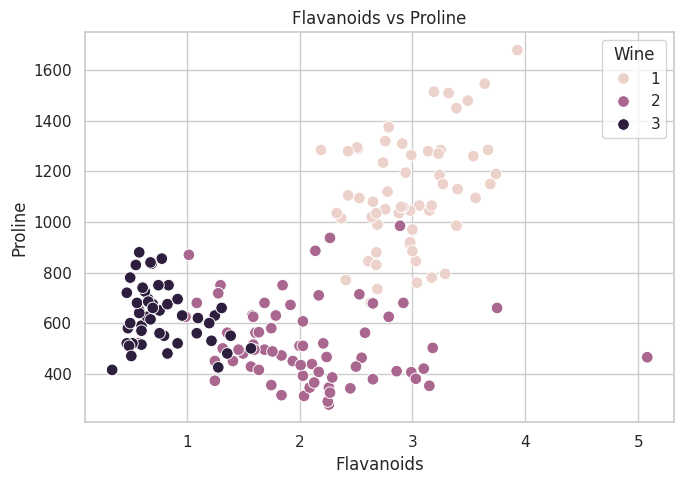

In [45]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='Flavanoids', y='Proline', hue=target_col, hue_order=order, s=70)

plt.title("Flavanoids vs Proline")
plt.xlabel("Flavanoids")
plt.ylabel("Proline")

plt.tight_layout()
plt.show()

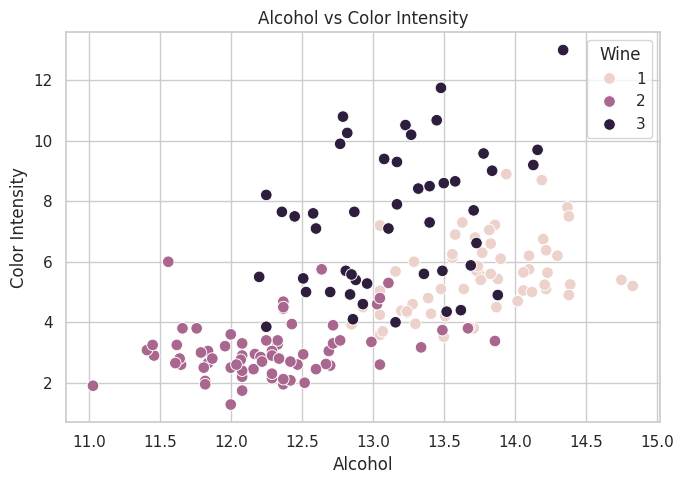

In [46]:
plt.figure(figsize=(7, 5))

sns.scatterplot(data=df, x='Alcohol', y='Color.int', hue=target_col, hue_order=order, s=70)

plt.title("Alcohol vs Color Intensity")
plt.xlabel("Alcohol")
plt.ylabel("Color Intensity")

plt.tight_layout()
plt.show()

In [47]:
outlier_summary = []

for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    outlier_summary.append([col, len(outliers), round(lower, 2), round(upper, 2)])

    print(f"{col:30s} : {len(outliers)}개 (Lower={lower:.2f}, Upper={upper:.2f})")

Alcohol                        : 0개 (Lower=10.39, Upper=15.65)
Malic.acid                     : 3개 (Lower=-0.62, Upper=5.30)
Ash                            : 3개 (Lower=1.69, Upper=3.08)
Acl                            : 4개 (Lower=10.75, Upper=27.95)
Mg                             : 4개 (Lower=59.50, Upper=135.50)
Phenols                        : 0개 (Lower=0.16, Upper=4.39)
Flavanoids                     : 0개 (Lower=-1.30, Upper=5.38)
Nonflavanoid.phenols           : 0개 (Lower=0.02, Upper=0.69)
Proanth                        : 2개 (Lower=0.20, Upper=3.00)
Color.int                      : 4개 (Lower=-1.25, Upper=10.67)
Hue                            : 1개 (Lower=0.28, Upper=1.63)
OD                             : 0개 (Lower=0.09, Upper=5.02)
Proline                        : 0개 (Lower=-226.25, Upper=1711.75)


In [48]:
for col in numeric_cols:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    if len(outliers) > 0:
        print(f"\n[{col} 이상치]")
        display(outliers[[col, target_col]])


[Malic.acid 이상치]


,Malic.acid,Wine
123,5.80,2
137,5.51,3
173,5.65,3



[Ash 이상치]


,Ash,Wine
25,3.22,1
59,1.36,2
121,3.23,2



[Acl 이상치]


...

,Proanth,Wine
95,3.28,2
110,3.58,2



[Color.int 이상치]


,Color.int,Wine
151,10.80,3
158,13.00,3
159,11.75,3
166,10.68,3



[Hue 이상치]


,Hue,Wine
115,1.71,2


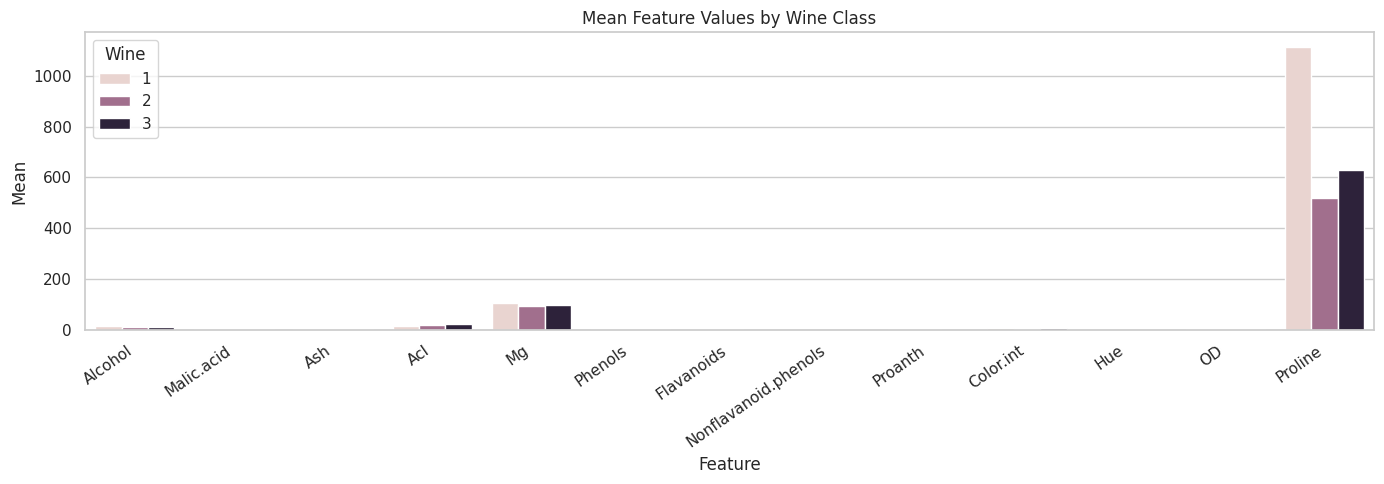

In [49]:
mean_raw_long = (
    df.groupby(target_col)[numeric_cols]
      .mean()
      .reset_index()
      .melt(
          id_vars=target_col,
          var_name="Feature",
          value_name="Mean"
      )
)

plt.figure(figsize=(14, 5))

sns.barplot(
    data=mean_raw_long,
    x="Feature",
    y="Mean",
    hue=target_col,
    hue_order=order
)

plt.title("Mean Feature Values by Wine Class")
plt.xlabel("Feature")
plt.ylabel("Mean")
plt.xticks(rotation=35, ha="right")

plt.tight_layout()
plt.show()

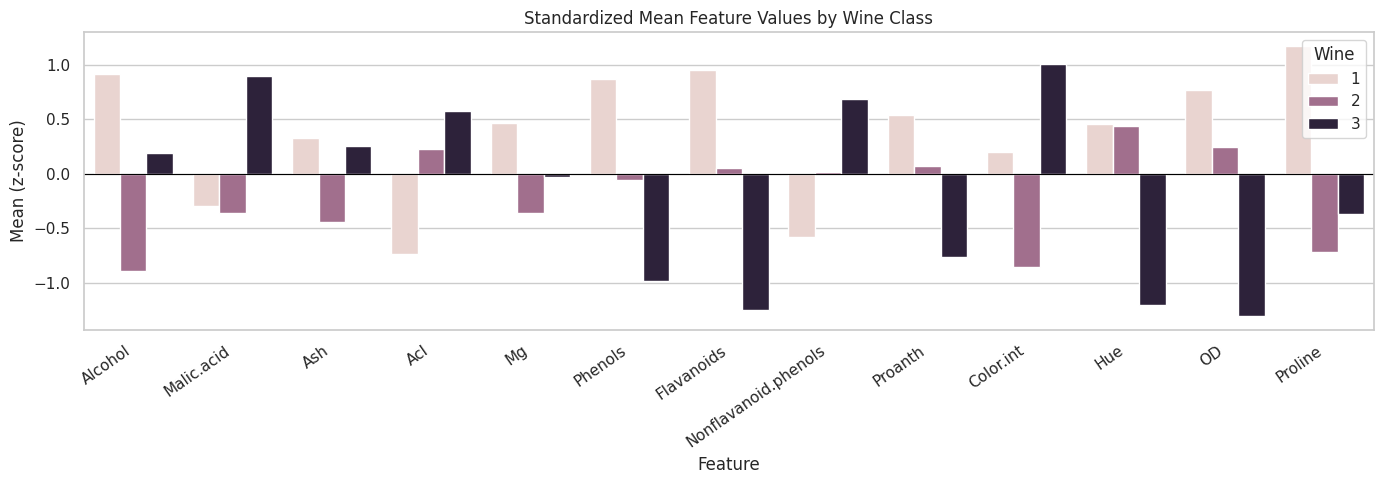

In [50]:
df_z = df.copy()
df_z[numeric_cols] = (df[numeric_cols] - df[numeric_cols].mean()) / df[numeric_cols].std()

mean_long = (
    df_z.groupby(target_col)[numeric_cols]
        .mean()
        .reset_index()
        .melt(id_vars=target_col, var_name="Feature", value_name="Mean (z-score)")
)

plt.figure(figsize=(14, 5))

sns.barplot(data=mean_long, x="Feature", y="Mean (z-score)", hue=target_col, hue_order=order)

plt.axhline(0, color='black', linewidth=0.8)
plt.title("Standardized Mean Feature Values by Wine Class")
plt.xticks(rotation=35, ha='right')

plt.tight_layout()
plt.show()

,CV
Flavanoids,0.492
Malic.acid,0.478
Color.int,0.458
Proline,0.422
Proanth,0.360
Nonflavanoid.phenols,0.344
Phenols,0.273
OD,0.272
Hue,0.239
Acl,0.171


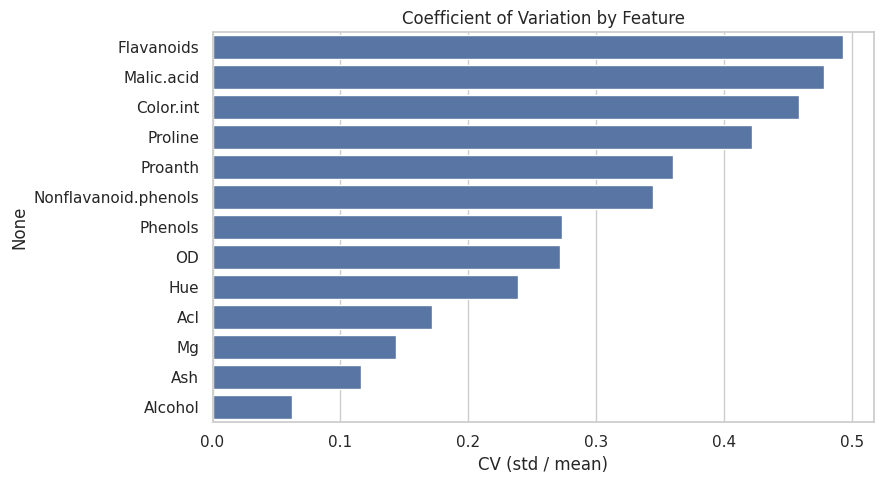

In [51]:
cv = (df[numeric_cols].std() / df[numeric_cols].mean()).sort_values(ascending=False)

display(cv.round(3).to_frame('CV'))

plt.figure(figsize=(9, 5))
sns.barplot(x=cv.values, y=cv.index)
plt.title("Coefficient of Variation by Feature")
plt.xlabel("CV (std / mean)")
plt.tight_layout()
plt.show()

,Feature,F,p-value
0,Flavanoids,233.9259,3.599e-50
1,Proline,207.9204,5.783e-47
2,OD,189.9723,1.393e-44
3,Alcohol,135.0776,3.320e-36
4,Color.int,120.6640,1.162e-33
5,Hue,101.3168,5.918e-30
6,Phenols,93.7330,2.138e-28
7,Malic.acid,36.9434,4.127e-14
8,Acl,35.7716,9.444e-14
9,Proanth,30.2714,5.125e-12


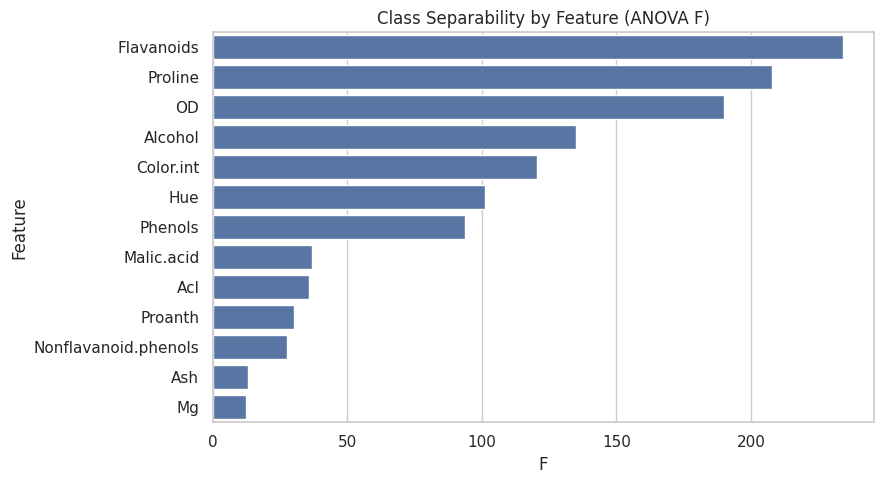

In [52]:
from scipy.stats import f_oneway

sep = []
for col in numeric_cols:
    groups = [g[col].values for _, g in df.groupby(target_col)]
    F, p = f_oneway(*groups)
    sep.append([col, F, p])

sep_df = pd.DataFrame(sep, columns=['Feature', 'F', 'p-value']).sort_values('F', ascending=False)
display(
    sep_df.reset_index(drop=True).style.format({
        "F": "{:.4f}",
        "p-value": "{:.3e}"
    })
)

plt.figure(figsize=(9, 5))
sns.barplot(data=sep_df, x='F', y='Feature')
plt.title("Class Separability by Feature (ANOVA F)")
plt.tight_layout()
plt.show()